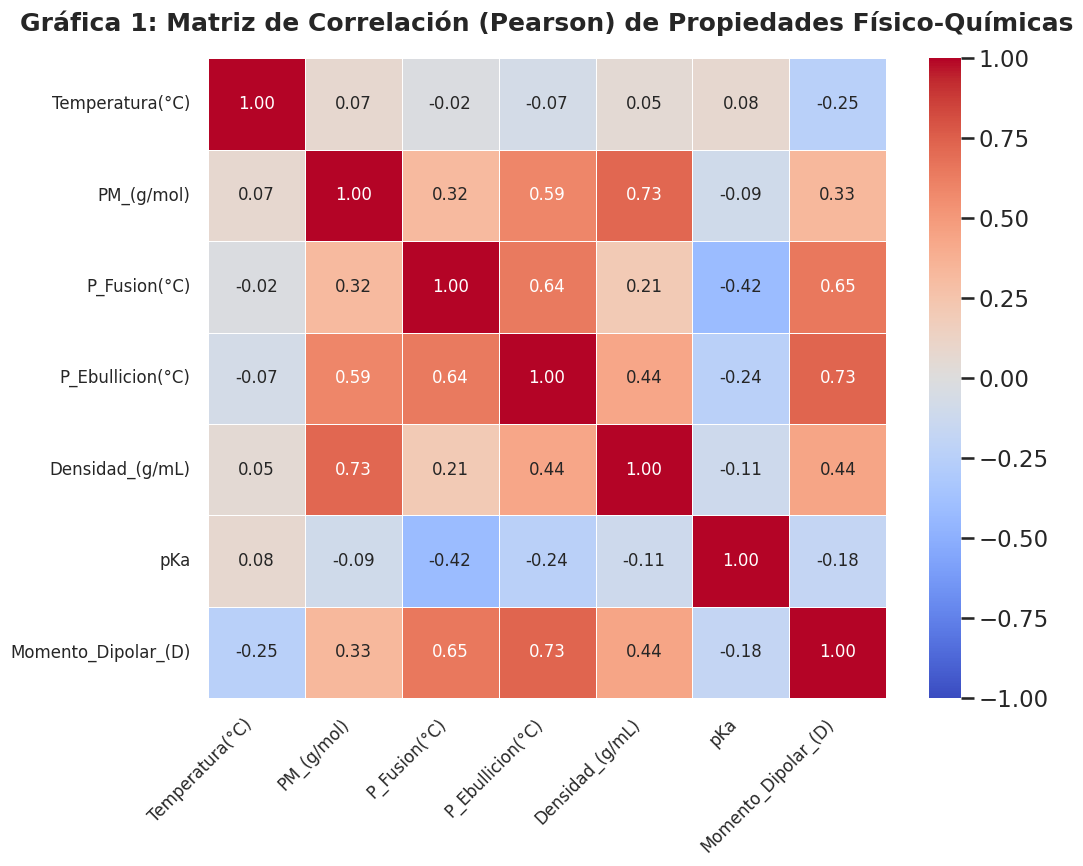

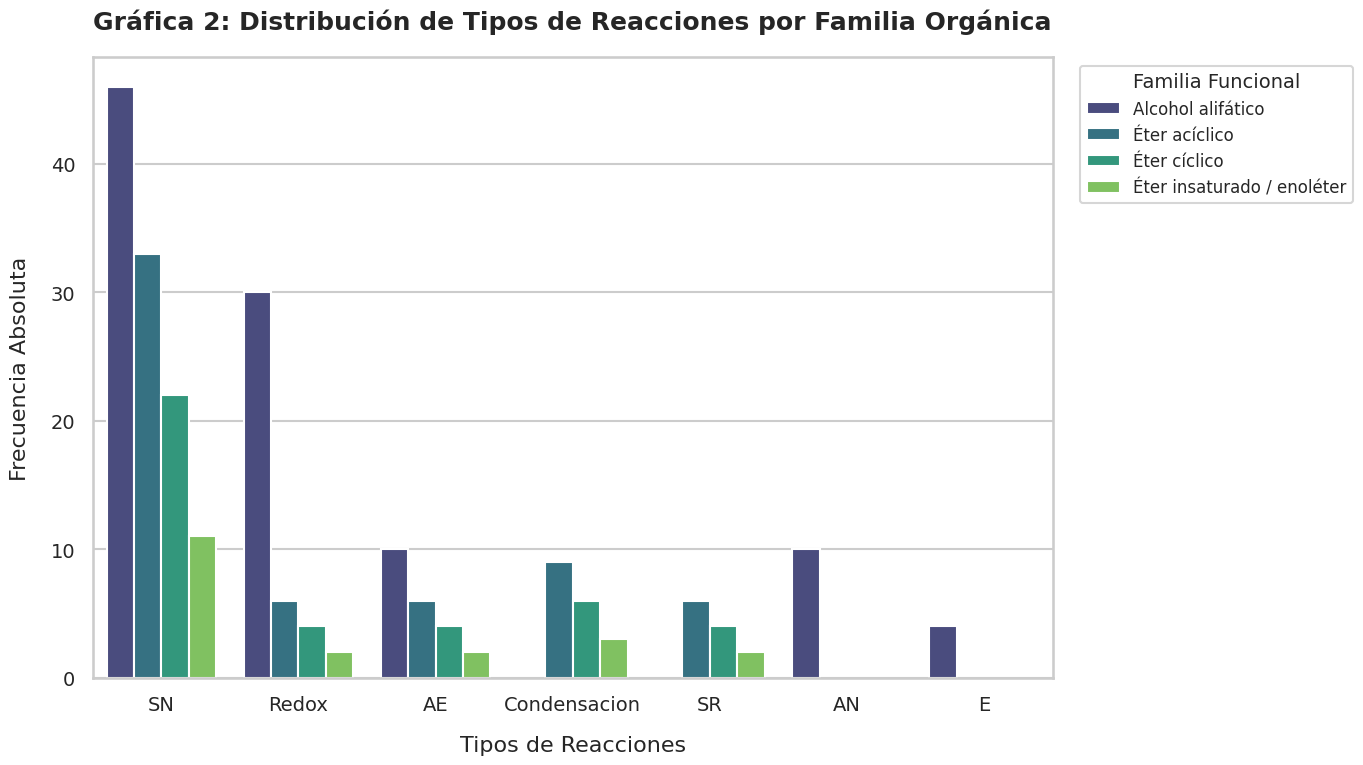

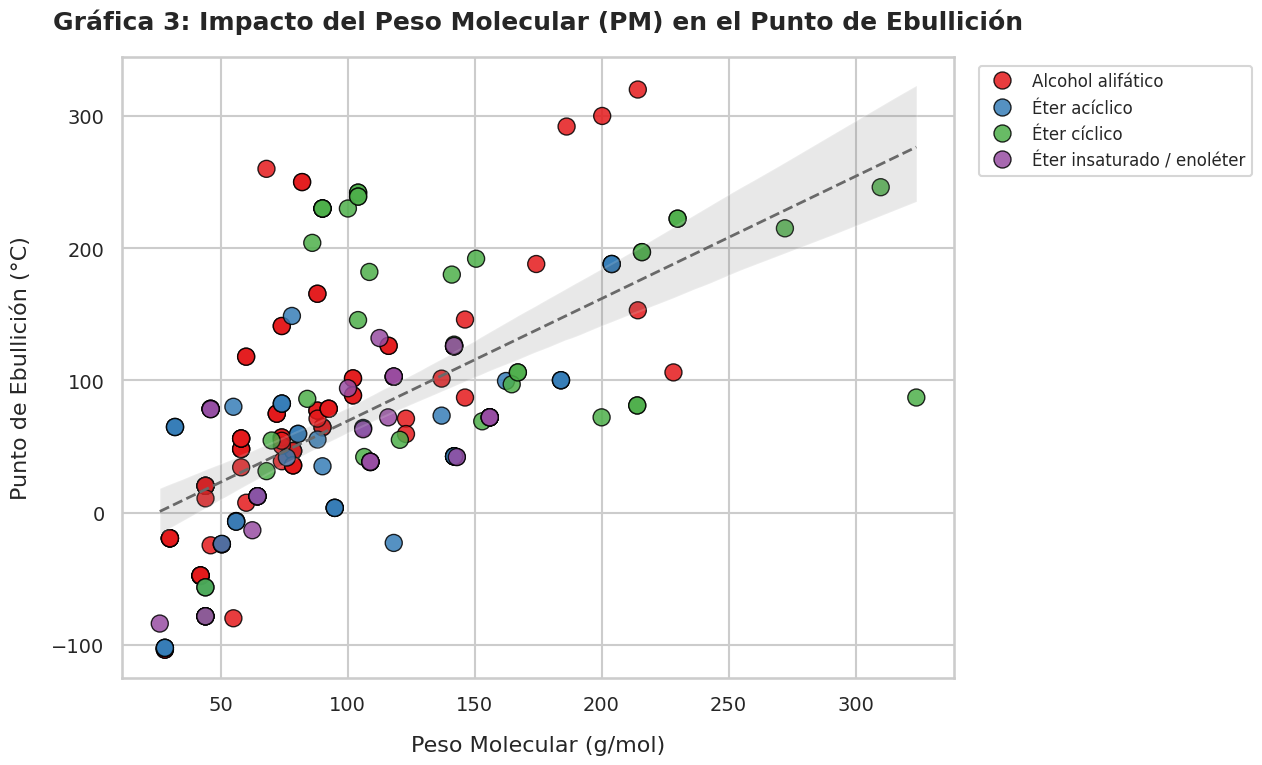

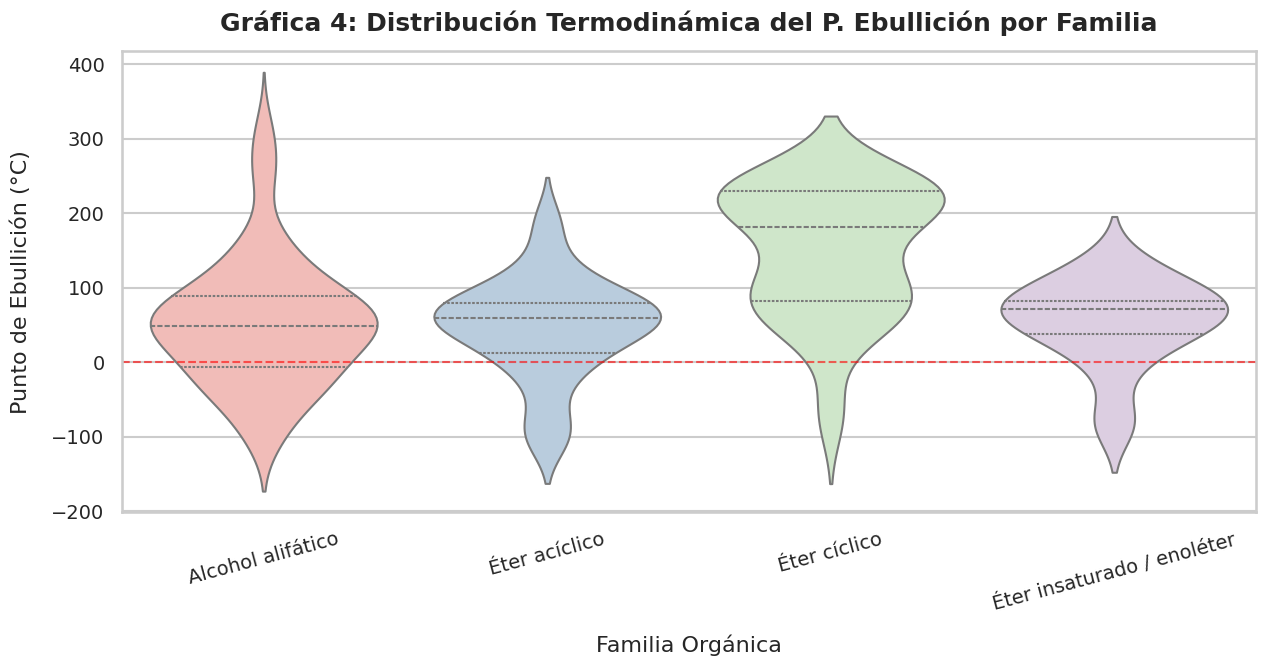

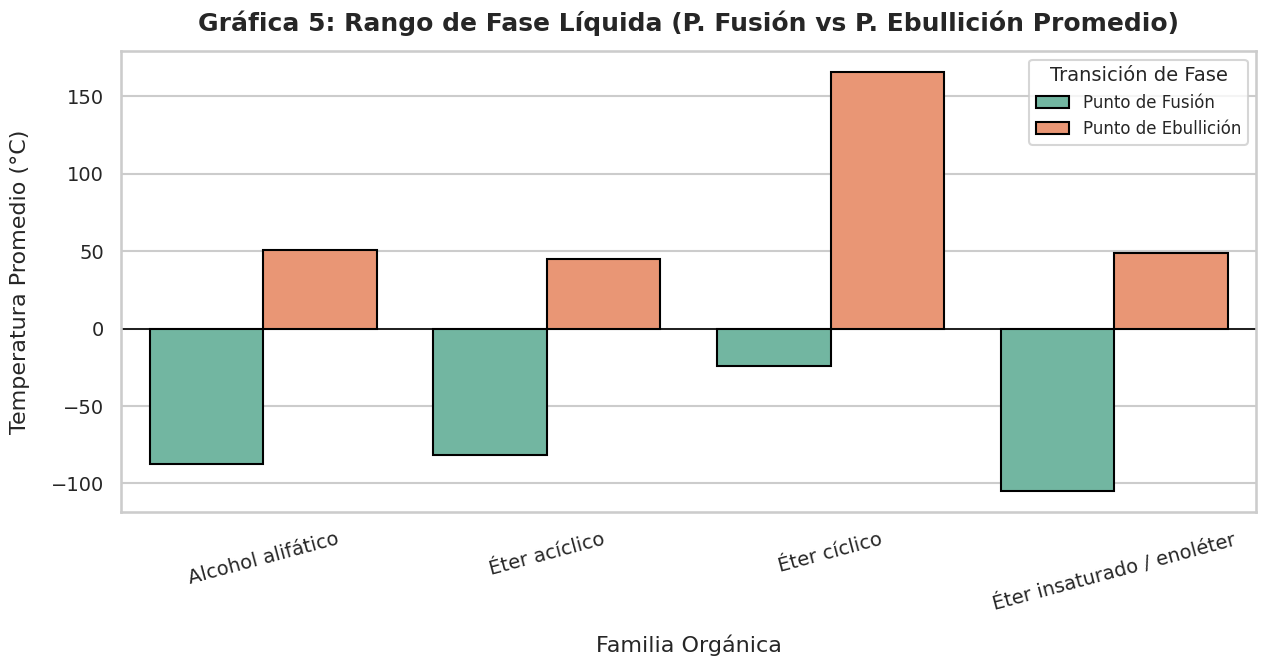

Ejecución completada sin errores. Las 5 gráficas se generaron y el archivo CSV fue exportado.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import glob

# ==============================================================================
# 1. CARGA Y LIMPIEZA DE DATOS
# ==============================================================================
archivos = glob.glob("matriz_quimica_organica_220_reacciones (7)*.xlsx")
file_path = archivos[0] if archivos else "Datos_Reacciones.xlsx"
df = pd.read_excel(file_path, sheet_name='Matriz_220_Transformaciones')

def clean_to_numeric(val):
    if pd.isna(val): return np.nan
    val_str = str(val).strip().lower().replace(',', '.')
    if val_str in ['reflujo', 'calor', 'ambiente', 'nan']: return np.nan
    if re.match(r'^\d+\.?\d*\s*-\s*\d+\.?\d*$', val_str):
        parts = val_str.split('-')
        return (float(parts[0]) + float(parts[1])) / 2.0
    match = re.search(r'[-+]?(?:\d+\.\d+|\d+)', val_str)
    if match: return float(match.group(0))
    return np.nan

cols_to_clean = [
    'Temperatura(°C)', 'PM_(g/mol)', 'P_Fusion(°C)', 'P_Ebullicion(°C)',
    'Densidad_(g/mL)', 'pKa', 'Momento_Dipolar_(D)'
]
for col in cols_to_clean:
    df[col] = df[col].apply(clean_to_numeric)

# Filtro físico para evitar sesgo por error de digitación en densidad (> 5 g/mL)
df.loc[df['Densidad_(g/mL)'] > 5.0, 'Densidad_(g/mL)'] = np.nan

# ==============================================================================
# 2. ESTANDARIZACIÓN CATEGÓRICA: TIPOS DE REACCIONES (SIGLAS)
# ==============================================================================
def mapear_siglas(mecanismo):
    m = str(mecanismo).lower()
    if 'radicalari' in m and 'sustit' in m: return 'SR'
    if 'radicalario' in m: return 'SR'
    if 'radicalari' in m and 'adic' in m: return 'AR'
    if 'sn' in m or ('sustituci' in m and 'nucleof' in m) or 'sustitución' in m: return 'SN'
    if 'electrofílica' in m and 'sustituci' in m: return 'SE'
    if 'adición electrofílica' in m or 'markovnikov' in m: return 'AE'
    if 'adición nucleofílica' in m: return 'AN'
    if 'e1' in m or 'e2' in m or 'eliminaci' in m: return 'E'
    if 'redox' in m or 'oxidaci' in m or 'reducci' in m or 'hidrogenaci' in m: return 'Redox'
    if 'condensaci' in m or 'eterificaci' in m or 'acoplamiento' in m or 'coordinaci' in m: return 'Condensacion'
    return 'SN'

df['Tipos_de_Reacciones'] = df['Tipo_Mecanismo'].apply(mapear_siglas)

# Configuración Estética Global
sns.set_theme(style="whitegrid", context="talk")

# ==============================================================================
# GRÁFICA 1: MATRIZ DE CORRELACIÓN
# ==============================================================================
plt.figure(figsize=(11, 9))
corr_matrix = df[cols_to_clean].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 12}
)
plt.title('Gráfica 1: Matriz de Correlación (Pearson) de Propiedades Físico-Químicas', fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICA 2: DISTRIBUCIÓN DE TIPOS DE REACCIONES
# ==============================================================================
plt.figure(figsize=(14, 8))
orden_reacciones = df['Tipos_de_Reacciones'].value_counts().index

sns.countplot(
    x='Tipos_de_Reacciones',
    hue='Familia',
    data=df,
    order=orden_reacciones,
    palette='viridis'
)

plt.title('Gráfica 2: Distribución de Tipos de Reacciones por Familia Orgánica', fontweight='bold', pad=20, fontsize=18)
plt.xlabel('Tipos de Reacciones', labelpad=15, fontsize=16)
plt.ylabel('Frecuencia Absoluta', labelpad=15, fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(title='Familia Funcional', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=12, title_fontsize=14)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICA 3: IMPACTO DEL PESO MOLECULAR EN EL PUNTO DE EBULLICIÓN
# ==============================================================================
plt.figure(figsize=(13, 8))
df_scatter = df.dropna(subset=['PM_(g/mol)', 'P_Ebullicion(°C)', 'Familia'])

sns.scatterplot(
    x='PM_(g/mol)',
    y='P_Ebullicion(°C)',
    hue='Familia',
    data=df_scatter,
    s=150,
    alpha=0.85,
    palette='Set1',
    edgecolor='black'
)
sns.regplot(
    x='PM_(g/mol)',
    y='P_Ebullicion(°C)',
    data=df_scatter,
    scatter=False,
    color='dimgrey',
    line_kws={'linestyle':'--', 'linewidth':2}
)

plt.title('Gráfica 3: Impacto del Peso Molecular (PM) en el Punto de Ebullición', fontweight='bold', pad=20, fontsize=18)
plt.xlabel('Peso Molecular (g/mol)', labelpad=15, fontsize=16)
plt.ylabel('Punto de Ebullición (°C)', labelpad=15, fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=12, title_fontsize=14)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICA 4: DISTRIBUCIÓN TERMODINÁMICA DEL PUNTO DE EBULLICIÓN (VIOLIN PLOT)
# ==============================================================================
plt.figure(figsize=(13, 7))
df_violin = df.dropna(subset=['Familia', 'P_Ebullicion(°C)'])

sns.violinplot(
    x='Familia',
    y='P_Ebullicion(°C)',
    data=df_violin,
    palette='Pastel1',
    inner='quartile',
    linewidth=1.5,
    hue='Familia',
    legend=False
)

plt.title('Gráfica 4: Distribución Termodinámica del P. Ebullición por Familia', fontweight='bold', pad=15, fontsize=18)
plt.xlabel('Familia Orgánica', labelpad=15, fontsize=16)
plt.ylabel('Punto de Ebullición (°C)', labelpad=15, fontsize=16)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.6)
plt.xticks(rotation=15, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICA 5: RANGO DE FASE LÍQUIDA (P. FUSIÓN VS P. EBULLICIÓN PROMEDIO)
# ==============================================================================
plt.figure(figsize=(13, 7))

# Reestructurar los datos usando 'df' ya limpio
df_fases = df.dropna(subset=['Familia', 'P_Fusion(°C)', 'P_Ebullicion(°C)'])
df_melt = df_fases.melt(
    id_vars=['Familia'],
    value_vars=['P_Fusion(°C)', 'P_Ebullicion(°C)'],
    var_name='Cambio_Fase',
    value_name='Temperatura (°C)'
)

df_melt['Cambio_Fase'] = df_melt['Cambio_Fase'].replace({
    'P_Fusion(°C)': 'Punto de Fusión',
    'P_Ebullicion(°C)': 'Punto de Ebullición'
})

sns.barplot(
    x='Familia',
    y='Temperatura (°C)',
    hue='Cambio_Fase',
    data=df_melt,
    palette='Set2',
    errorbar=None,
    edgecolor='black'
)

plt.title('Gráfica 5: Rango de Fase Líquida (P. Fusión vs P. Ebullición Promedio)', fontweight='bold', pad=15, fontsize=18)
plt.xlabel('Familia Orgánica', labelpad=15, fontsize=16)
plt.ylabel('Temperatura Promedio (°C)', labelpad=15, fontsize=16)
plt.axhline(0, color='black', linewidth=1.2)
plt.xticks(rotation=15, fontsize=14)
plt.yticks(fontsize=14)
plt.legend(title='Transición de Fase', fontsize=12, title_fontsize=14)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. EXPORTACIÓN LIMPIA PARA POWER BI
# ==============================================================================
df.to_csv('Datos_Reacciones_PowerBI_Optimizados.csv', index=False, encoding='utf-8-sig')
print("Ejecución completada sin errores. Las 5 gráficas se generaron y el archivo CSV fue exportado.")